# 05. Streaming: many metrics, guardrails, and multiple-testing correction

**The decision:** the recommendation team trained a new algorithm and wants to know
whether it can replace the one in production. The question sounds simple, but the
problem is not one metric, it is several at once: watch time (the primary metric),
number of sessions, completion rate, and a buffering guardrail (which must not get
worse). Launching means getting all of those reads right at the same time, without
being fooled by chance.

This chapter closes the use-cases track. The core lesson is about statistical
discipline: when you look at many metrics, the chance of finding a "win" that is
pure noise grows fast, and a senior scientist corrects for that before celebrating.
We will measure that inflation, apply a multiple-testing correction, and, most
importantly, learn to read a null result honestly.

Fundamentals behind this chapter:
[IV. Inference](../../../docs/en/theory/04-inference.md) (topic 16) and
[V. Diagnostics](../../../docs/en/theory/05-diagnostics.md) (topic 21).


## The natural reflex (and why it is not enough)

The instinct is direct: run a test on each of the four metrics, each at
`alpha = 0.05`, and celebrate any winner. It looks harmless, each test on its own
is calibrated to be wrong only 5% of the time under the null.

The trouble shows up when you look at the whole **family** of tests at once. With
several independent nulls, the chance of **at least one** false positive does not
stay at 5%: it inflates well above that. This is exactly why we must correct for
multiple testing. Before correcting, let us measure how big the problem is.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


def _find_data():
    """Locate examples/use_cases/data whether run from the notebook or the root."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base / "data", base / "examples" / "use_cases" / "data"):
            if (cand / "ecommerce_checkout.csv").exists():
                return cand
    raise FileNotFoundError("Could not locate examples/use_cases/data")


DATA = _find_data()

df = pd.read_csv(DATA / "streaming_metrics.csv")
print(df.shape)
df.head()

(5000, 10)


,user_id,plan,watch_time_y0,watch_time_y1,sessions_y0,sessions_y1,completion_y0,completion_y1,buffering_y0,buffering_y1
0,1,premium,41.359,44.359,5.226,5.276,0.3902,0.3902,6.461,6.481
1,2,premium,75.691,78.691,5.097,5.147,0.5797,0.5797,15.437,15.457
2,3,basic,57.682,60.682,7.078,7.128,0.5751,0.5751,3.214,3.234
3,4,premium,42.266,45.266,4.385,4.435,0.7226,0.7226,7.311,7.331
4,5,premium,26.068,29.068,6.970,7.020,0.4861,0.4861,4.962,4.982


## The family-wise error inflates

With `K` independent nulls, each tested at `alpha`, the probability of **at least
one** false positive is `1 - (1 - alpha)^K`. For `K = 4` at `alpha = 0.05` that is
about 18.5%: nearly one in five "wins" would be pure noise. The formula is analytic,
but it is worth confirming by simulation to be sure the number is not an artifact of
reasoning.


In [2]:
K, alpha = 4, 0.05
print(f"analytic P(>=1 false positive), {K} independent nulls: {1 - (1 - alpha) ** K:.1%}")

rng = np.random.default_rng(505)
sims = 20000
any_fp = sum(bool((rng.random(K) < alpha).any()) for _ in range(sims))
print(f"simulated                                        : {any_fp / sims:.1%}")

analytic P(>=1 false positive), 4 independent nulls: 18.5%
simulated                                        : 18.0%


## One allocation, several metrics

A subtle point that separates people who understand experimentation from people who
just run tests: there are not four experiments here, there is **one**. The same
users were randomized a single time, and that same allocation applies to every
metric. Randomizing again for each metric would be mixing up different experiments.

So we assign once with `CRD` and reuse it. For each metric, we build the observed
outcome (the treatment value where `t == 1`, the control value otherwise) and
estimate the effect with `NeymanCI`.


In [3]:
from skxperiments.core.assignment import CRDAssignment
from skxperiments.design.crd import CRD
from skxperiments.estimators.difference_in_means import DifferenceInMeans
from skxperiments.inference import NeymanCI

design = CRD(p=0.5, seed=505)
base = design.randomize(df[["plan"]].copy())
t = base.data_[base.treatment_col_].to_numpy()

metrics = ["watch_time", "sessions", "completion", "buffering"]
results = {}
for m in metrics:
    data = base.data_.copy()
    data[m] = np.where(t == 1, df[f"{m}_y1"].to_numpy(), df[f"{m}_y0"].to_numpy())
    a = CRDAssignment(data=data, treatment_col=base.treatment_col_, design=design, seed=505)
    results[m] = NeymanCI(estimator=DifferenceInMeans(outcome_col=m)).fit(a).estimate()

{m: round(r.p_value, 4) for m, r in results.items()}

{'watch_time': 0.0057,
 'sessions': 0.2736,
 'completion': 0.0543,
 'buffering': 0.1472}

## Multiple-testing correction (FWER, Holm)

With four metrics in the family, we control the **family-wise error rate** (FWER)
with Holm's method. Holm is a sequential adjustment of the p-values: it guarantees
that the probability of **any** false positive across the whole family stays at
`alpha`, and it is more powerful than the classic Bonferroni without giving up that
strict guarantee.

`ExperimentComparison` applies the correction over the family and returns a
ready-made table with the raw and corrected p-values, plus a forest plot to see the
effects and their intervals side by side.


experiment     ate  p_value  p_value_corrected  significant
watch_time  2.8323   0.0057             0.0226         True
  sessions  0.0627   0.2736             0.2945        False
completion -0.0097   0.0543             0.1629        False
 buffering  0.1689   0.1472             0.2945        False


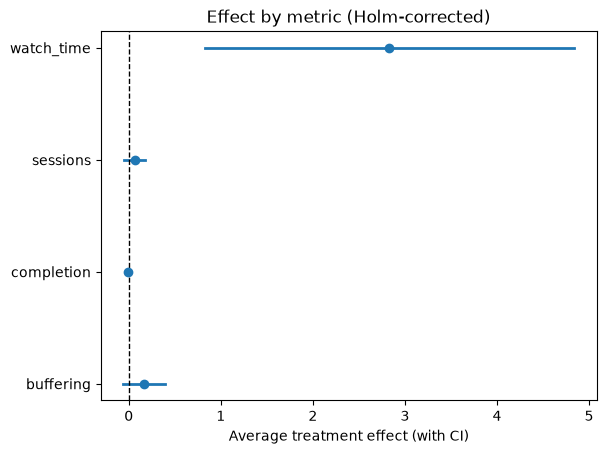

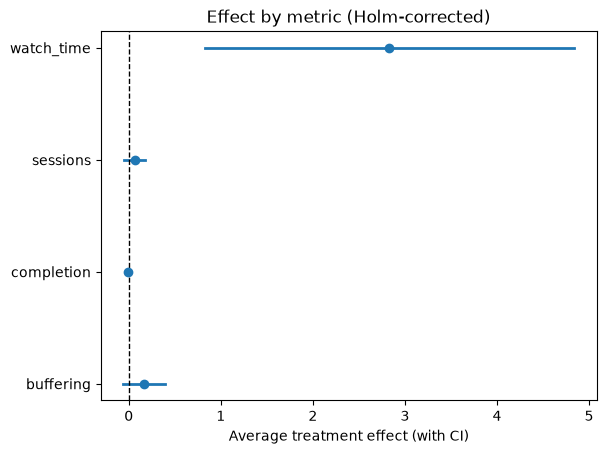

In [4]:
from skxperiments.pipeline import ExperimentComparison
from skxperiments.reporting import plot_forest

comparison = ExperimentComparison(correction="holm", alpha=0.05).run(results)
display_cols = ["experiment", "ate", "p_value", "p_value_corrected", "significant"]
print(comparison.table[display_cols].round(4).to_string(index=False))

ax = plot_forest(comparison)
ax.set_title("Effect by metric (Holm-corrected)")
ax.figure

## Reading the null and the guardrail (honest limits)

Only watch time survives the correction. Here is the honest reading a senior
scientist insists on, and that an API tutorial tends to hide.

**Sessions and completion being "not significant" is NOT "proven to have no
effect".** Absence of evidence is not evidence of absence: those metrics are simply
underpowered to rule out small effects. They come out inconclusive, not zeroed.

**The buffering guardrail being "not flagged" is not the same as "certified
safe".** A guardrail calls for **non-inferiority** thinking (prove it did not get
meaningfully worse), and a two-sided "not significant" does not establish that on
its own. `skxperiments` v1 has **no** dedicated non-inferiority or equivalence test,
so treat a clean guardrail as "no alarm", not "proven harmless".

**One more choice worth naming:** Holm controls the family-wise error (strict, any
false positive counts) and is right for a launch gate; Benjamini-Hochberg controls
the false discovery rate (FDR, laxer) and is better for exploratory sweeps over many
metrics. The choice depends on the cost of being wrong.


## Pipeline and report on the primary metric

To close, we run `ExperimentPipeline` on the primary metric. Beyond inference, it
runs the `SRMTest` automatically (the sample-ratio mismatch diagnostic we saw in the
earlier chapters), making sure the 50/50 allocation did not break. Then we generate
an HTML `ExperimentReport`, ready to share with whoever makes the call.


In [5]:
from skxperiments.diagnostics import SRMTest
from skxperiments.pipeline import ExperimentPipeline

data = base.data_.copy()
data["watch_time"] = np.where(t == 1, df["watch_time_y1"].to_numpy(), df["watch_time_y0"].to_numpy())
primary = CRDAssignment(data=data, treatment_col=base.treatment_col_, design=design, seed=505)

pipeline_result = ExperimentPipeline(
    inference=NeymanCI(estimator=DifferenceInMeans(outcome_col="watch_time")),
    diagnostics=[SRMTest()],
).run(primary)
print(f"watch_time ATE={pipeline_result.results.ate:.3f}, "
      f"p={pipeline_result.results.p_value:.4f}, flagged={pipeline_result.flagged}")

watch_time ATE=2.832, p=0.0057, flagged=False


ate,se,ci,p_value,alpha,n_obs,n_treated,n_control,estimator_name,design_name,inference_name,variance_type,inference_mode
2.832319,1.023486,"(0.8263226219991826, 4.83831497800081)",0.005652,0.05,5000,2500,2500,DifferenceInMeans,CRD,NeymanCI,neyman,finite_population

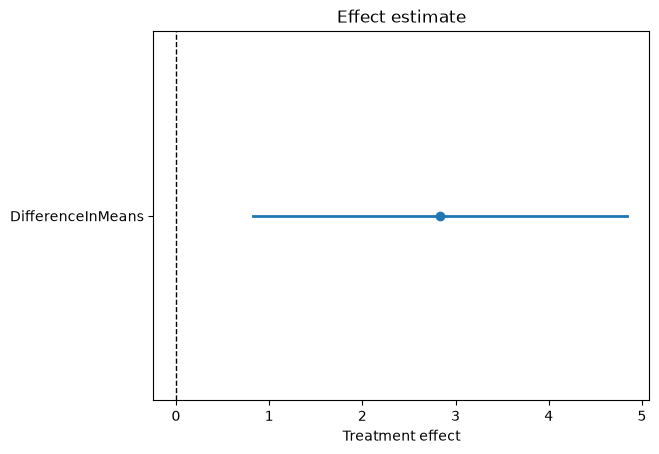
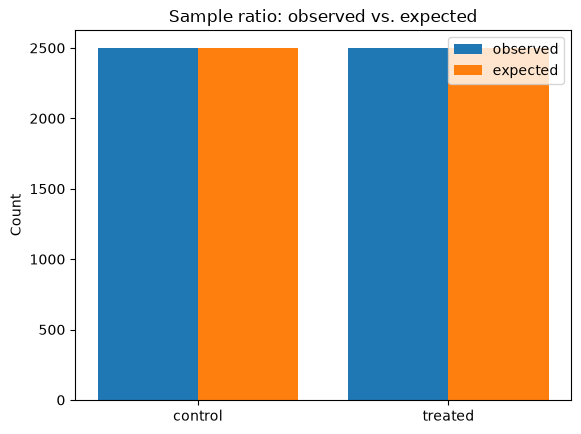

In [6]:
from IPython.display import HTML

from skxperiments.reporting import ExperimentReport

report = ExperimentReport(pipeline_result, title="Streaming recommender - watch time")
HTML(report.to_html())

## Decision, limits, and closing

The true effect on watch time is **+3 minutes**, the only real one, and it survives
the Holm correction; the guardrail raises no alarm. **Recommendation: launch**, while
monitoring buffering closely and treating the secondary metrics as inconclusive, not
null. That discipline, telling "we do not know" apart from "there is no effect", is
what separates a defensible decision from wishful thinking with a p-value.

Limits of this chapter, said honestly:
1. No non-inferiority or equivalence test for guardrails in v1: a clean guardrail is
   "no alarm", not proof of safety.
2. Holm assumes the family is exactly these four metrics: pre-register the metric
   family before looking at the data, or the FWER guarantee dilutes.
3. No per-metric variance reduction was applied: CUPED would tighten the reads and
   give the secondary metrics more power.

With that, we close the use-cases track. For the fundamentals behind each piece, see
the [theory series](../../../docs/en/theory/01-foundations.md).
